In [37]:
#  Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,precision_score,recall_score,f1_score,ConfusionMatrixDisplay

In [38]:
#  Load dataset
df=pd.read_csv("Telco_Data_Practice__cleaned.csv")

In [39]:
#  Investigate dataset shape
df.shape

(7043, 13)

In [40]:
#  Investigate dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   InternetService   7043 non-null   str    
 7   Contract          7043 non-null   str    
 8   PaperlessBilling  7043 non-null   str    
 9   PaymentMethod     7043 non-null   str    
 10  MonthlyCharges    7043 non-null   float64
 11  TotalCharges      7043 non-null   str    
 12  Churn             7043 non-null   str    
dtypes: float64(1), int64(2), str(10)
memory usage: 1.1 MB


In [41]:
#  First five rows
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,DSL,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,DSL,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,DSL,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,DSL,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,Fiber optic,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [42]:
#  Last five rows
df.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,Male,0,Yes,Yes,24,Yes,DSL,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Fiber optic,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,DSL,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Fiber optic,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,Male,0,No,No,66,Yes,Fiber optic,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [43]:
#  Treat incorrect data type
data=df.copy()
data["TotalCharges"]=pd.to_numeric(data["TotalCharges"],errors="coerce")

In [44]:
# Check duplicated values
data.duplicated().sum()

np.int64(23)

In [45]:
# Treat duplicated values
data=data.drop_duplicates()

In [46]:
# Check data inconsistence
for col in data.select_dtypes(include="str").columns:
    print(data[col].value_counts())
    print()

gender
Male      3540
Female    3480
Name: count, dtype: int64

Partner
No     3618
Yes    3402
Name: count, dtype: int64

Dependents
No     4910
Yes    2110
Name: count, dtype: int64

PhoneService
Yes    6338
No      682
Name: count, dtype: int64

InternetService
Fiber optic    3090
DSL            2418
No             1512
Name: count, dtype: int64

Contract
Month-to-month    3852
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling
Yes    4160
No     2860
Name: count, dtype: int64

PaymentMethod
Electronic check             2359
Mailed check                 1596
Bank transfer (automatic)    1544
Credit card (automatic)      1521
Name: count, dtype: int64

Churn
No     5163
Yes    1857
Name: count, dtype: int64



In [47]:
data.shape

(7020, 13)

In [48]:
# check impossible values for numerical values
for col in data.select_dtypes(include="number").columns:
    a=data[col]<0
    if a.sum()>0:
        print(data.loc[a,col])
    else:continue

In [49]:
# Checking null values
data.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
InternetService      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

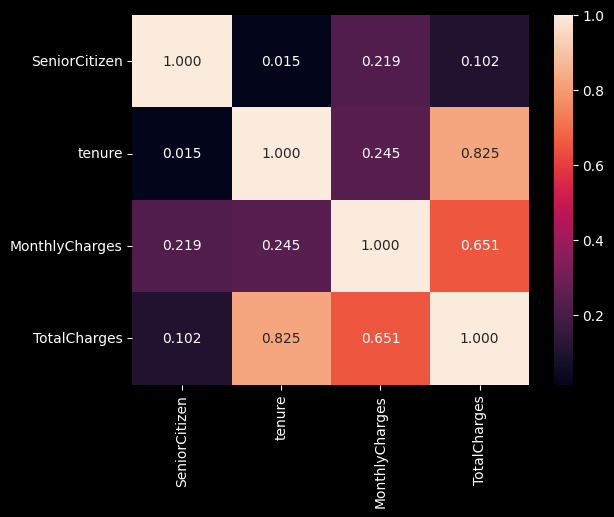

In [50]:
# Checking Multicollineality
dt=data.select_dtypes(include="number").columns
corr=data[dt].corr()
sns.heatmap(
    corr,
    fmt=".3f",
    annot=True
)
plt.show()

PREPROCESSING

In [51]:
# Encode Binary columns
data["Churn"]=data["Churn"].replace({
        "No":0,
        "Yes":1

    })
data["Churn"]=pd.to_numeric(data["Churn"],errors="coerce")

In [52]:
# Separate feature and label
feature=data.drop(columns="Churn")
target=data["Churn"]

In [53]:
#  Separate categorical cols
categorical_cols=data.select_dtypes(include="str").columns
categorical_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

In [54]:
# Separate numerical columns
numerical_cols=(data.select_dtypes(include="number").columns).drop("Churn")
numerical_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [55]:
#  Initiate numerical pipeline
numerical_pipeline=Pipeline([
    ("num_impute",SimpleImputer(strategy='mean')),
    ("scaler",StandardScaler())
])

In [56]:
# Initiate Categorical pipeline
categorical_pipeline=Pipeline([
    ("cat_impute",SimpleImputer(strategy='most_frequent')),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [57]:
preprocessor=ColumnTransformer([
    ("num",numerical_pipeline,numerical_cols),
    ("cat",categorical_pipeline,categorical_cols)
]
)

In [58]:
# Initiate Main pipeline
pipeline=Pipeline([
    ("preprocessing",preprocessor),
    ("model",LogisticRegression())
])

In [59]:
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

In [60]:
# Split train and test data
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    test_size=0.2,
    random_state=42
)

In [61]:
x_train.shape

(5616, 12)

In [62]:
x_test.shape

(1404, 12)

In [63]:
y_train.shape

(5616,)

In [64]:
y_test.shape

(1404,)

TRAINING MODEL

In [65]:
pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

In [66]:
print(help(ConfusionMatrixDisplay))

Help on class ConfusionMatrixDisplay in module sklearn.metrics._plot.confusion_matrix:

class ConfusionMatrixDisplay(builtins.object)
 |  ConfusionMatrixDisplay(confusion_matrix, *, display_labels=None)
 |
 |  Confusion Matrix visualization.
 |
 |  It is recommended to use
 |  :func:`~sklearn.metrics.ConfusionMatrixDisplay.from_estimator` or
 |  :func:`~sklearn.metrics.ConfusionMatrixDisplay.from_predictions` to
 |  create a :class:`ConfusionMatrixDisplay`. All parameters are stored as
 |  attributes.
 |
 |  For general information regarding `scikit-learn` visualization tools, see
 |  the :ref:`Visualization Guide <visualizations>`.
 |  For guidance on interpreting these plots, refer to the
 |  :ref:`Model Evaluation Guide <confusion_matrix>`.
 |
 |  Parameters
 |  ----------
 |  confusion_matrix : ndarray of shape (n_classes, n_classes)
 |      Confusion matrix.
 |
 |  display_labels : ndarray of shape (n_classes,), default=None
 |      Display labels for plot. If None, display labels

EVALUATION AFTER TRAINING

Recall: 0.549
Precision: 0.6558
f1 score: 0.5977


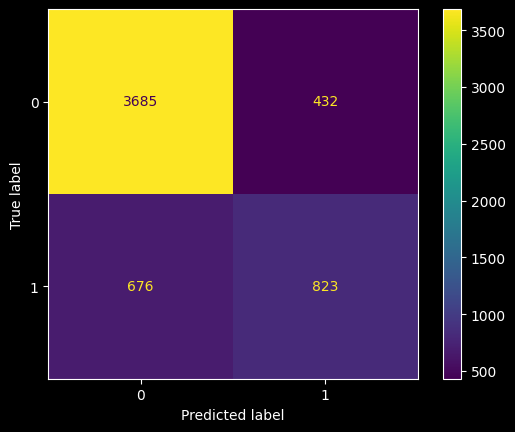

In [ ]:
y_train_predict=pipeline.predict(x_train)
precision=precision_score(y_train,y_train_predict)
recall=recall_score(y_train,y_train_predict)
f1=f1_score(y_train,y_train_predict)
print(f"""Recall: {round(recall,4)}
Precision: {round(precision,4)}
f1 score: {round(f1,4)}""")
conf_train=ConfusionMatrixDisplay.from_predictions(y_train,y_train_predict)


TESTING MODEL

In [68]:
y_predicted=pipeline.predict(x_test)

Recall: 0.5447
Precision: 0.625
f1 score: 0.5821
0.8005698005698005


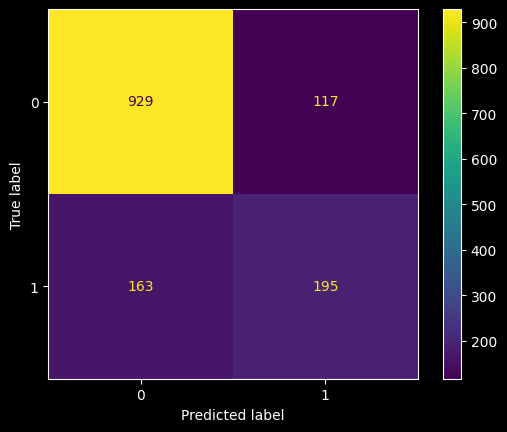

In [69]:
# Evaluation after testng tehe model
precision=precision_score(y_test,y_predicted)
recall=recall_score(y_test,y_predicted)
f1=f1_score(y_test,y_predicted)
print(f"""Recall: {round(recall,4)}
Precision: {round(precision,4)}
f1 score: {round(f1,4)}""")
conf_train=ConfusionMatrixDisplay.from_predictions(y_test,y_predicted)
print(pipeline.score(x_test,y_test))

In [70]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


KNN

In [71]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
k_value=[x for x in range(1,251)]
results=[]
for k in k_value:
    model=Pipeline([
        ("preprocessing",preprocessor),
        ("model",KNeighborsClassifier(n_neighbors=k))
    ])
    scores=cross_val_score(
        model,
        x_train,
        y_train,
        cv=5,
        scoring='accuracy'

    )
    results.append({
        "k":k,
        "score":scores,
        "cv_score_mean":scores.mean(),
        "cv_score_std":scores.std()
    })

: 

In [ ]:
score_table=pd.DataFrame(results)

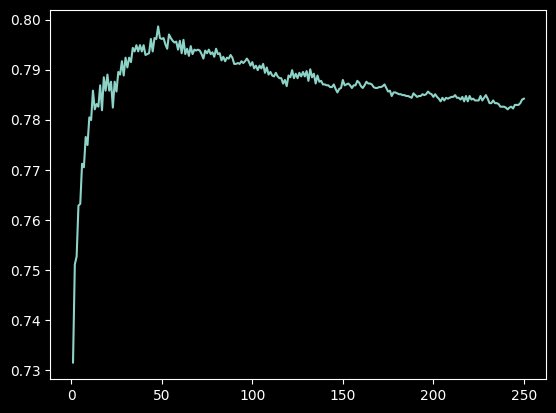

In [ ]:
plt.plot(
    score_table["k"],
    score_table["cv_score_mean"]
)
plt.show()

In [ ]:
score_table

,k,score,cv_score_mean,cv_score_std
0,1,"[0.7206405693950177, 0.730186999109528, 0.7319...",0.731483,0.006225
1,2,"[0.7455516014234875, 0.7462154942119323, 0.753...",0.751069,0.004326
2,3,"[0.74644128113879, 0.736420302760463, 0.760463...",0.752672,0.010827
3,4,"[0.7660142348754448, 0.7471059661620659, 0.759...",0.762820,0.009071
4,5,"[0.7660142348754448, 0.7435440783615316, 0.767...",0.763176,0.010288
...,...,...,...,...
245,246,"[0.800711743772242, 0.7684772929652716, 0.7880...",0.782938,0.010838
246,247,"[0.8016014234875445, 0.7666963490650045, 0.788...",0.782938,0.011726
247,248,"[0.802491103202847, 0.767586821015138, 0.78984...",0.783294,0.011918
248,249,"[0.8042704626334519, 0.767586821015138, 0.7898...",0.784006,0.012352


In [ ]:
a=score_table["cv_score_mean"].max()
b=score_table["cv_score_mean"]==a
display(score_table.loc[b])
c=score_table["k"]==54
display(score_table.loc[c])

,k,score,cv_score_mean,cv_score_std
47,48,"[0.8167259786476868, 0.792520035618878, 0.8112...",0.798608,0.013064


,k,score,cv_score_mean,cv_score_std
53,54,"[0.8096085409252669, 0.7969723953695459, 0.801...",0.797006,0.008077


In [ ]:
# Finaly model training
f_model=Pipeline([
    ("preprocessing",preprocessor),
    ("model",KNeighborsClassifier(n_neighbors=54))
])
f_model.fit(x_train,y_train)
print(f"Training score: {round(f_model.score(x_train,y_train),4)}")

Training score: 0.8025


In [ ]:
y_predicteded=f_model.predict(x_test)
f_model.score(x_train,y_train)
acc=f_model.score(x_test,y_test)
print(f"Testinig score: {round(acc,4)}")

Testinig score: 0.802


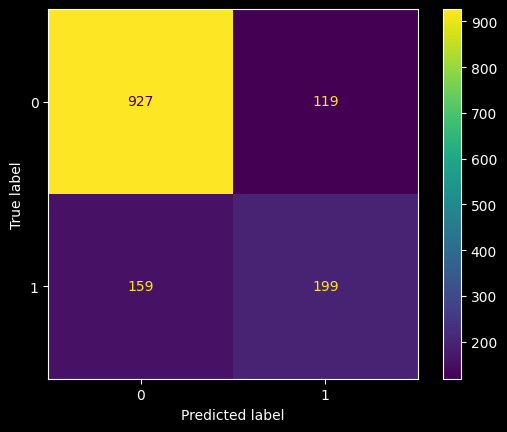

In [ ]:
con=ConfusionMatrixDisplay.from_predictions(y_test,y_predicteded)

In [ ]:
print(f1_score(y_test,y_predicteded))

0.5887573964497042
